In [1]:
import numpy as np

from scipy import integrate as inte
from scipy import linalg

from scipy.optimize import fsolve

import networkx as netx

import itertools

import random

# from jupyterthemes import jtplot

# jtplot.style(theme='grade3',context='talk',fscale=1.0, spines=True, gridlines='--')

import matplotlib.pyplot as plt

import matplotlib.cm as cm

import matplotlib.gridspec as gridspec

import matplotlib.image as mpimg

from mpl_toolkits.mplot3d import Axes3D

import cycler


In [2]:
## ipyml interactive figures
# %matplotlib widget  

## static figures
# %matplotlib inline  

plt.rcParams['axes.labelsize'] = 16  # Adjust as needed
plt.rcParams['xtick.labelsize'] = 13 # For tick labels on x-axis
plt.rcParams['ytick.labelsize'] = 13 # For tick labels on y-axis
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['axes.grid'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

rng = np.random.default_rng()


In [3]:
from sympy import *
from sympy.stats import Uniform, sample
from sympy.plotting import plot3d
import spb as spb
from spb import *

In [4]:
# from spb.defaults import cfg, set_defaults
# # display(cfg)

# cfg["axis_fontsize"] = 20 # Adjust label font size
# cfg["tick_fontsize"] = 15 # Adjust tick font size

# set_defaults(cfg)

## 2 species case:

In [145]:
eps,k_12,k_21,a_1,a_2,r_1,d_2,alpha = symbols('eps k_12 k_21 a_1 a_2 r_1 d_2 alpha', positive=True, real=True)

In [146]:
v1 = Matrix([[ a_1, -eps*k_12*alpha]])
v2 = Matrix([[ k_12*alpha, a_2]])

## Unit vectors along the direction of columns of -A

In [147]:
b1 = v1/v1.norm()
b2 = v2/v2.norm()

In [148]:
Omega = (1/2*pi)*acos(b1.dot(b2))

In [149]:
d_Omega = diff(Omega, alpha)

In [150]:
root_dOmega = solve(d_Omega, alpha)

In [151]:
root_dOmega

[sqrt(a_1)*sqrt(a_2)/(sqrt(eps)*k_12)]

## Maximizing power to find $\alpha_{pow}$

In [152]:
## Start by constructing A

A_mat = -Matrix( [v1, v2] ).T
r = Matrix( [[ r_1, -d_2 ]] ).T

N_mat = A_mat.solve(-r)  ## Find equilibrium

In [153]:
A_mat

Matrix([
[          -a_1, -alpha*k_12],
[alpha*eps*k_12,        -a_2]])

In [154]:
N_mat

Matrix([
[     (a_2*r_1 + alpha*d_2*k_12)/(a_1*a_2 + alpha**2*eps*k_12**2)],
[(-a_1*d_2 + alpha*eps*k_12*r_1)/(a_1*a_2 + alpha**2*eps*k_12**2)]])

In [155]:
P_out = eps*k_12*alpha*N_mat[0]*N_mat[1]

In [156]:
P_out

alpha*eps*k_12*(-a_1*d_2 + alpha*eps*k_12*r_1)*(a_2*r_1 + alpha*d_2*k_12)/(a_1*a_2 + alpha**2*eps*k_12**2)**2

In [157]:
dPout = diff(P_out, alpha)

In [158]:
dPout

-4*alpha**2*eps**2*k_12**3*(-a_1*d_2 + alpha*eps*k_12*r_1)*(a_2*r_1 + alpha*d_2*k_12)/(a_1*a_2 + alpha**2*eps*k_12**2)**3 + alpha*d_2*eps*k_12**2*(-a_1*d_2 + alpha*eps*k_12*r_1)/(a_1*a_2 + alpha**2*eps*k_12**2)**2 + alpha*eps**2*k_12**2*r_1*(a_2*r_1 + alpha*d_2*k_12)/(a_1*a_2 + alpha**2*eps*k_12**2)**2 + eps*k_12*(-a_1*d_2 + alpha*eps*k_12*r_1)*(a_2*r_1 + alpha*d_2*k_12)/(a_1*a_2 + alpha**2*eps*k_12**2)**2

In [159]:
root_dPout = solve(dPout,alpha)

In [160]:
print(root_dPout[2])  ## This is \alpha_{pow}

(sqrt(a_1)*sqrt(a_1*d_2**2 + a_2*eps*r_1**2) + a_1*d_2)/(eps*k_12*r_1)


In [161]:
root_dPout[2].subs({a_1:1, a_2:4, k_12:2, r_1:1, d_2:0.5, eps:0.1})

6.53112887414927

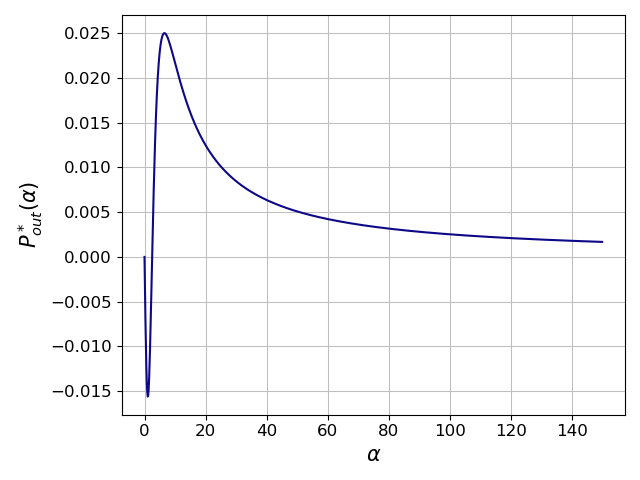

In [163]:

MB.colorloop = [ cm.plasma.colors[120*i] for i in range(3) ]

plt2 = spb.plot(P_out.subs({a_1:1, a_2:4, k_12:2, r_1:1, d_2:0.5, eps:0.1}), (alpha, 0, 150), xlabel = r'$\alpha$', ylabel = r'$P_{out}^*(\alpha)$', show = False, axis=True)
plt2.show()
plt.close('all')

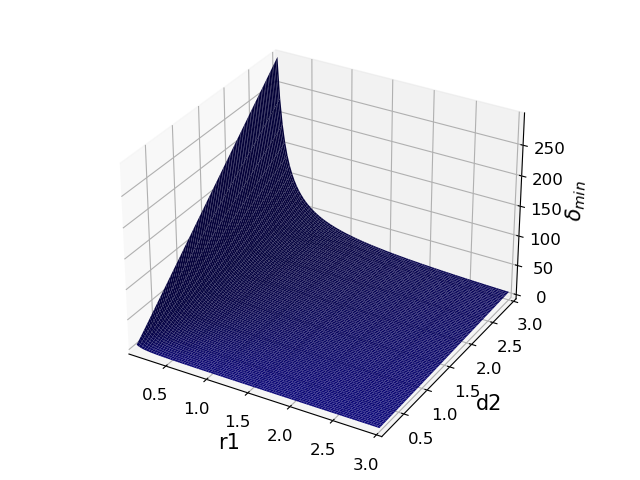

In [164]:
## Define alpha_pow from beta_pow

alpha_pow = root_dPout[2]

alpha_minfeas = sqrt(a_1*a_2/(eps*k_12))   ## alpha_minfeas is the alpha that minimizes feasibility

## Note that alpha_minfeas is independent of the r vector

dist_minfeas = alpha_pow - alpha_minfeas

plt_dist = plot3d(dist_minfeas.subs({a_1:1, a_2:4, k_12:2, eps:0.1}), (r_1, 0.1, 3), (d_2, 0.1, 3), xlabel='r1', ylabel='d2', zlabel=r'$\delta_{min}$', show=False)
plt_dist.show()
plt.close('all')

## Can rewrite $\alpha_{pow}$ in terms of the ratio of r1 and d2. 
Define ratio as $\rho$. Then:
$\alpha_{pow} = \dfrac{a_1 + \sqrt{ a_1^2 + \varepsilon a_1 a_2 \rho^2}}{\varepsilon k_{12}\rho}$

In [171]:
## Plot versus the ratio of r1 and d2

rho = symbols('rho', positive=True, real=True)

alpha_pow_rho = (sqrt(a_1**2 + eps*a_1*a_2*rho**2) + a_1)/(eps*k_12*rho)

alpha_minfeas = root_dOmega[0]

dist_minfeas_rho = abs( alpha_pow_rho - alpha_minfeas )

plt_ratio = spb.plot(dist_minfeas_rho.subs({a_1:1, a_2:4, k_12:2, eps:0.1}), (rho, 0.1, 10), xlabel=r'$\rho = \dfrac{r_1}{d_2}$', ylabel=r'Distance between $\alpha_{\Omega min}$ and $\alpha_{pow}$' + '\n' + r'$\delta_{min}$', show=False, grid=False)
plt_ratio.save('rho_deltamin_2sp.eps', dpi=600, bbox_inches='tight')
# plt_ratio.show()
plt.close('all')

## 3 species general case:

In [23]:
a_1, a_2, a_3, r_1, d_2, d_3, k_12, k_23, eps, alpha = symbols('a_1 a_2 a_3 r_1 d_2 d_3 k_12 k_23 eps alpha', positive=True, real=True)

In [24]:
v1 = Matrix([[ a_1, -eps*k_12*alpha, 0 ]])
v2 = Matrix([[ k_12*alpha, a_2, -eps*k_23*alpha ]])
v3 = Matrix( [[ 0, k_23*alpha, a_3 ]] )

### Unit vectors along the direction of columns of -A

In [25]:
b1 = v1/v1.norm()
b2 = v2/v2.norm()
b3 = v3/v3.norm()

### Construct matrix with unit vectors b1, b2 and b3 as columns

In [26]:
b_mat = Matrix( [b1, b2, b3] ).T

### Feasibility probability

In [27]:
Omega = (1/(2*pi))*atan( Abs( b_mat.det())/( 1 + b1.dot(b2) + b2.dot(b3) + b3.dot(b1) ) )

### Maximize output power to find $\alpha_{pow}$

In [28]:
## Start by constructing A

A_mat = -Matrix( [v1, v2, v3] ).T
r = Matrix( [[ r_1, -d_2, -d_3 ]] ).T

N_mat = A_mat.solve(-r)  ## Find equilibrium

In [29]:
A_mat

Matrix([
[          -a_1,    -alpha*k_12,           0],
[alpha*eps*k_12,           -a_2, -alpha*k_23],
[             0, alpha*eps*k_23,        -a_3]])

In [30]:
P_out = eps*k_23*alpha*N_mat[1]*N_mat[2]

In [31]:
d_Pout = diff(P_out, alpha)

In [32]:
root_dPout = solve(d_Pout, alpha)

In [33]:
root_dPout[2]

(-a_1*a_2*d_3*k_23 + sqrt(a_2)*sqrt(a_1**2*a_2*d_3**2*k_23**2 + a_1**2*a_3*d_2**2*eps*k_23**2 + 2*a_1*a_2*a_3*d_3*eps*k_12*k_23*r_1 + a_1*a_3**2*d_2**2*eps*k_12**2 + a_2*a_3**2*eps**2*k_12**2*r_1**2) - a_2*a_3*eps*k_12*r_1)/(a_1*d_2*eps*k_23**2 + a_3*d_2*eps*k_12**2)

### We find that root_dPout[2] is $\alpha_{pow}$

In [34]:
alpha_pow = root_dPout[2]

### Plot equilibrium densities of resource, consumer and predator

In [36]:
root_Rstar = solve(N_mat[0].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, eps:0.1, r_1:1, d_2:0.5, d_3:0.1}), alpha)

# # Top and basal parameters swapped
# root_Rstar = solve(N_mat[0].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, eps:0.1, r_1:4, d_2:0.2, d_3:0.1}), alpha)

In [37]:
root_Cstar = solve(N_mat[1].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, eps:0.1, r_1:1, d_2:0.5, d_3:0.1}), alpha)

# # Top and basal parameters swapped
# root_Cstar = solve(N_mat[1].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, eps:0.1, r_1:4, d_2:0.2, d_3:0.1}), alpha)

In [38]:
root_Pstar = solve(N_mat[2].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, eps:0.1, r_1:1, d_2:0.5, d_3:0.1}), alpha)

# # Top and basal parameters swapped
# root_Pstar = solve(N_mat[2].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, eps:0.1, r_1:4, d_2:0.2, d_3:0.1}), alpha)

In [39]:
alpha_min = max(root_Rstar, root_Cstar, root_Pstar)[0]

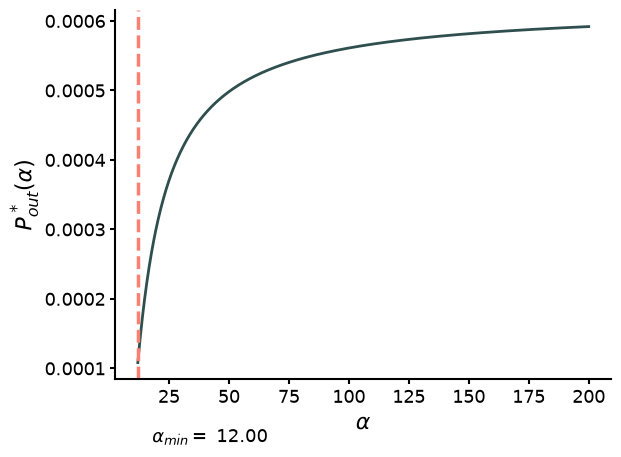

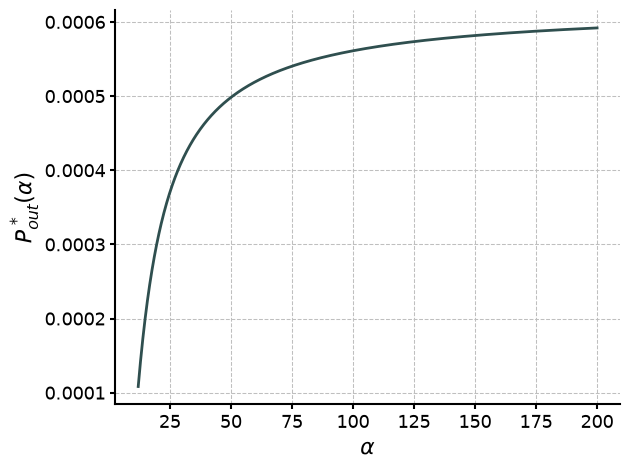

In [21]:
plt2 = spb.plot(P_out.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, r_1:1, d_2:0.5, d_3:0.1, eps:0.1}), (alpha, alpha_min, 200), xlabel = r'$\alpha$', ylabel = r'$P_{out}^*(\alpha)$', label = '', rendering_kw={"color": "darkslategray", "linewidth": 2} , legend = True, show = False)

# # Top and basal parameters swapped
# plt2 = spb.plot(P_out.subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, r_1:4, d_2:0.2, d_3:0.1, eps:0.1}), (alpha, alpha_min, 200), xlabel = r'$\alpha$', ylabel = r'$P_{out}^*(\alpha)$', label = '', legend = True, show = False)

axplt2 = plt2.ax
axplt2.axvline(x=alpha_min, color='salmon', linestyle='--', linewidth=2.5)#, label=r'$\alpha_{min}=$ %.2f' %alpha_min)

axplt2.text(alpha_min*1.5, 0, r'$\alpha_{min}=$ %.2f' %alpha_min, color='k', va='center', fontsize=13)

# axplt2.legend()
# plt.setp(axplt2.get_legend().get_texts(), fontsize=14)
axplt2.grid(False)
# plt2.save('Pow_alpha_3sp.png', dpi=600, bbox_inches='tight')
plt2.show()

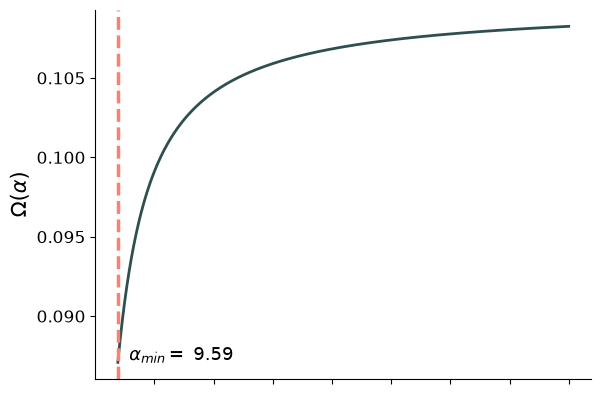

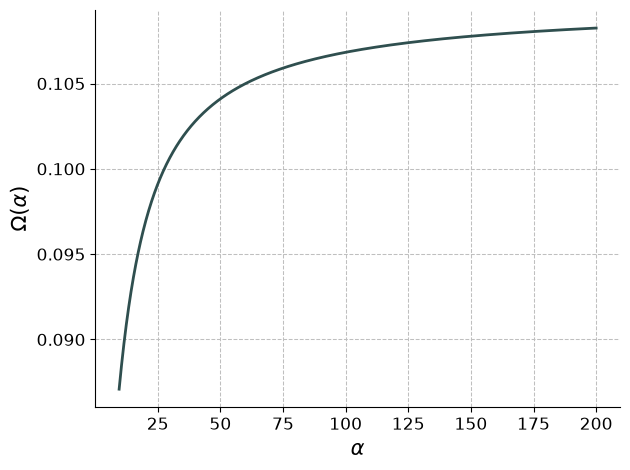

In [44]:
plt_omega = spb.plot(Omega.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, eps:0.1}), (alpha, alpha_min, 200), ylabel = r'$\Omega(\alpha)$', label = '', rendering_kw={"color": "darkslategray", "linewidth": 2} , show=False, axis=True)

## Top and basal parameters swapped
# plt_omega = spb.plot(Omega.subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, eps:0.1}), (alpha, alpha_min, 200), ylabel = r'$\Omega(\alpha)$', label = '', show=False, axis=True)

ax_feas = plt_omega.ax
ax_feas.axvline(x=alpha_min, color='salmon', linestyle='--', linewidth=2.5)
ax_feas.text(alpha_min*1.5, 0.0875, r'$\alpha_{min}=$ %.2f' %alpha_min, color='k', va='center', fontsize=13)
ax_feas.set_xticklabels([])
ax_feas.xaxis.set_label_text("")

ax_feas.grid(False)
# plt_omega.save('feas_alpha_3swap.eps', dpi=600, bbox_inches='tight')
plt_omega.show()

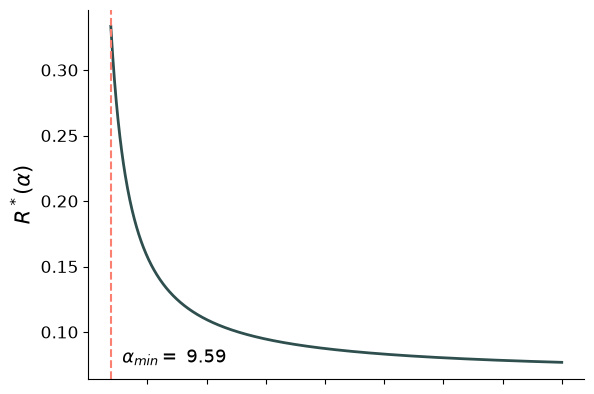

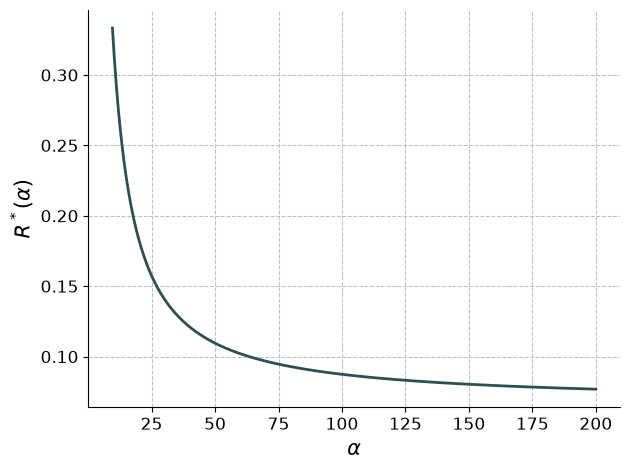

In [47]:
plt_rstar = spb.plot(N_mat[0].subs({ a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, eps:0.1, r_1:1, d_2:0.5, d_3:0.1 }), (alpha, alpha_min, 200), ylabel = r'$R^*(\alpha)$', label = '', rendering_kw={"color": "darkslategray", "linewidth": 2} , show=False, axis=True)

ax_r3sp = plt_rstar.ax
ax_r3sp.axvline(x=alpha_min, color='salmon', linestyle='--')
ax_r3sp.text(alpha_min*1.5, 0.08, r'$\alpha_{min}=$ %.2f' %alpha_min, color='k', va='center', fontsize=13)
ax_r3sp.set_xticklabels([])
ax_r3sp.xaxis.set_label_text("")

ax_r3sp.grid(False)

# plt_rstar.save('rstar_alpha_3sp.eps', dpi=600, bbox_inches='tight')
plt_rstar.show()

In [67]:
plt.close('all')

### Create a panel of subplots

### Normal pyramid $a_1=1, a_2=4, a_3=9$

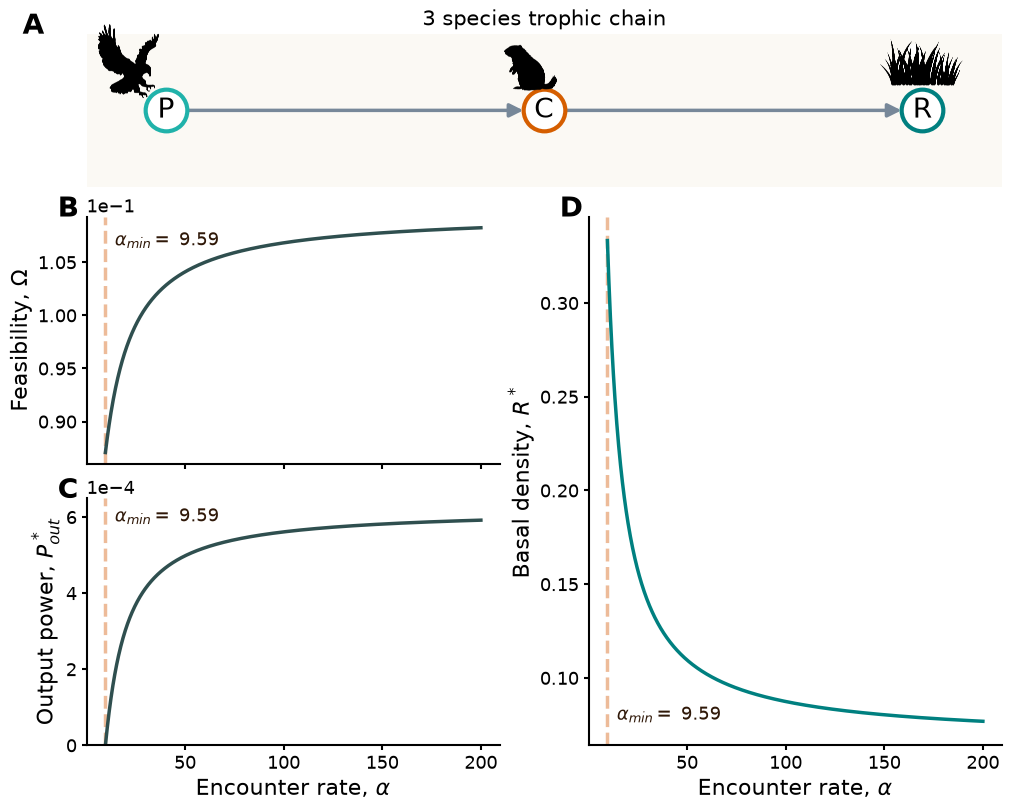

In [40]:
# MB.colorloop = [ cm.plasma.colors[120*i] for i in range(3) ]

fig = plt.figure(figsize=(10, 8), constrained_layout=True) 
## ^ constrained layout prevents overlaps between subplots

gs = gridspec.GridSpec(ncols=4, nrows=8, figure=fig)

ax2 = fig.add_subplot(gs[0:2, 0:4])
ax1 = fig.add_subplot(gs[2:5, 0:2])
ax3 = fig.add_subplot(gs[5:8, 0:2])
ax4 = fig.add_subplot(gs[2:8, 2:4])

# ax1.grid(True)
# # ax2.grid(True)
# ax3.grid(True)
# ax4.grid(True)

p1 = spb.plot(Omega.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, eps:0.1}), (alpha, alpha_min, 200), ylabel = r'Feasibility, $\Omega$', xlabel = '', label = '', ax=ax1, rendering_kw={"color": "darkslategray", "linewidth": 2.5} , grid=False, show=False)
ax1.axvline(x=alpha_min, color='#EDBB99', linestyle='--', linewidth=2.5)
ax1.text(alpha_min*1.5, 0.107, r'$\alpha_{min}=$ %.2f' %alpha_min, color='#2F1808', va='center', fontsize=13)
ax1.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# ax1.legend()

ax1.xaxis.set_tick_params(labelbottom=False)


trophic_chain = netx.Graph()
node_list = ["R", "C", "P"]
trophic_chain.add_nodes_from(node_list)
# pos = netx.kamada_kawai_layout(trophic_chain)
pos = {'P': (0, 0), 'C': (1, 0), 'R': (2, 0)}
# netx.draw(trophic_chain, pos, node_color='goldenrod', ax=ax2, with_labels = True)
relation_list = [['P', 'C'], ['C', 'R']]
trophic_chain = netx.from_edgelist(relation_list, create_using=netx.DiGraph)
netx.draw_networkx_nodes(trophic_chain, pos, nodelist=node_list[2], ax=ax2, node_size=900, linewidths=3.0, node_color='white', node_shape='o', edgecolors="lightseagreen", alpha=1)
netx.draw_networkx_nodes(trophic_chain, pos, nodelist=node_list[1], ax=ax2, node_size=900, linewidths=3.0, node_color='white', node_shape='o', edgecolors="#D55E00", alpha=1)
netx.draw_networkx_nodes(trophic_chain, pos, nodelist=node_list[0], ax=ax2, node_size=900, linewidths=3.0, node_color='white', node_shape='o', edgecolors="teal", alpha=1)
netx.draw_networkx_labels(trophic_chain, pos, ax=ax2, font_size=20, font_color="k")
netx.draw_networkx_edges(trophic_chain, pos, width=2.5, ax=ax2, node_size=900, edge_color='lightslategray', arrowsize=20, alpha=1)

# Load external images
graph_species = {
    'R': mpimg.imread('Canva_grass.png'),
    'C': mpimg.imread('Canva_rodent.png'),
    'P': mpimg.imread('Canva_raptor.png'),
}


# Transform coordinates and overlay images on each node
ax_transform = ax2.transData.transform
fig_transform = fig.transFigure.inverted().transform

imsize = 0.1  # Relative size of the image icon

xrel_shift = imsize*np.asarray([1.4, 0, -1.6])  ## Different shifts to position different nodes
xrel_iter = iter(xrel_shift)

yrel_shift = imsize*np.asarray([0.8, 0.75, 0.9])
yrel_iter = iter(yrel_shift)

for node, (x, y) in pos.items():
    if node in graph_species:
        # Convert data coordinates to figure-relative coordinates
        xx, yy = ax_transform((x, y))
        xa, ya = fig_transform((xx, yy))

        xrel_curr = next(xrel_iter)
        yrel_curr = next(yrel_iter)
        
        # Create a small axes at the node position to display the image
        image_ax = fig.add_axes([xa - (imsize + xrel_curr) / 2, ya + (imsize + yrel_curr) / 2, imsize, imsize])
        image_ax.imshow(graph_species[node])
        image_ax.set_aspect('equal')
        image_ax.axis('off')

# netx.draw(trophic_chain, pos, edge_color='goldenrod', ax=ax2, with_labels=True, font_size = 15, node_size=500, width = 2.5, arrowsize=20)
# edge_lab = netx.draw_networkx_edge_labels(trophic_chain, pos, ax=ax2, font_size=15, verticalalignment='bottom', edge_labels={('P','C'):r'$\alpha$', ('C','R'):r'$\alpha$'})

# for text_obj in edge_lab.values():
#     text_obj.set_va("bottom") 

#     text_obj.set_bbox(
#             dict(facecolor="white", edgecolor="none", pad=5)
#         ) 

ax2.set_axis_on()
ax2.set_title('3 species trophic chain', fontsize=15)
ax2.spines[:].set_visible(False)
ax2.set_facecolor("#FBF9F4")


p2 = spb.plot(P_out.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, r_1:1, d_2:0.5, d_3:0.1, eps:0.1}), (alpha, alpha_min, 200), xlabel = r'Encounter rate, $\alpha$', ylabel = r'Output power, $P_{out}^*$', label = '', ax=ax3, rendering_kw={"color": "darkslategray", "linewidth": 2.5} , grid=False, show=False)
ax3.axvline(x=alpha_min, color='#EDBB99', linestyle='--', linewidth=2.5)#, label=r'$\alpha_{min}=$ %.2f' %alpha_min)
ax3.text(alpha_min*1.5, 0.0006, r'$\alpha_{min}=$ %.2f' %alpha_min, color='#2F1808', va='center', fontsize=13)
ax3.set_ylim(top=0.00065)
ax3.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
# ax3.legend()


p3 = spb.plot(N_mat[0].subs({ a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, eps:0.1, r_1:1, d_2:0.5, d_3:0.1 }), (alpha, alpha_min, 200), xlabel = r'Encounter rate, $\alpha$', ylabel = r'Basal density, $R^*$', label = '', ax=ax4, rendering_kw={"color": "teal", "linewidth": 2.5} , grid=False, show=False)
ax4.axvline(x=alpha_min, color='#EDBB99', linestyle='--', linewidth=2.5)#, label=r'$\alpha_{min}=$ %.2f' %alpha_min)
ax4.text(alpha_min*1.5, 0.08, r'$\alpha_{min}=$ %.2f' %alpha_min, color='#2F1808', va='center', fontsize=13)
# ax4.legend()

## Add corner labels
ax2.annotate('A', xy=(0, 0.95), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax1.annotate('B', xy=(0, 0.95), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax3.annotate('C', xy=(0, 0.95), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax4.annotate('D', xy=(0, 0.95), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)

p1.draw()
p2.draw()
p3.draw()

# plt.setp(ax1.get_legend().get_texts(), fontsize=14)
# plt.setp(ax3.get_legend().get_texts(), fontsize=14)
# plt.setp(ax4.get_legend().get_texts(), fontsize=14)

plt.show()
# plt.savefig('3_sp.png', dpi=600, bbox_inches='tight')
# plt.close('all')

### Inverted pyramid $a_1=9, a_2=4, a_3=1$

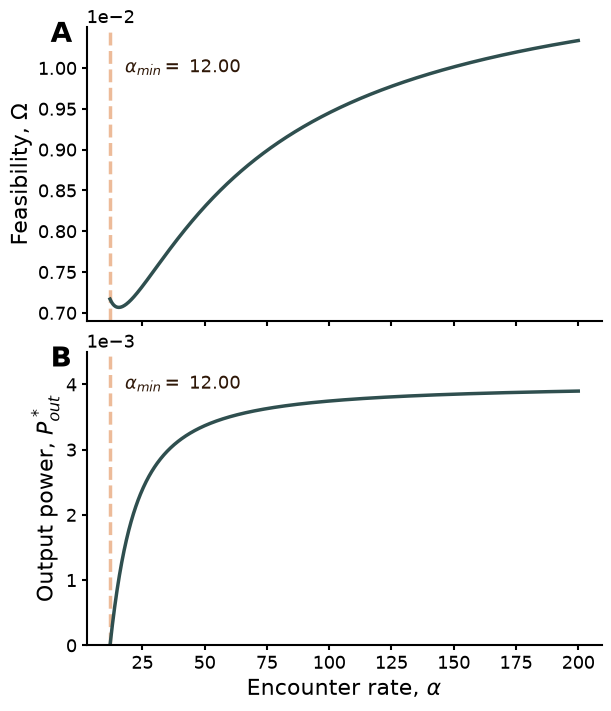

In [69]:
fig = plt.figure(figsize=(6, 7), constrained_layout=True) 
## ^ constrained layout prevents overlaps between subplots

gs = gridspec.GridSpec(ncols=1, nrows=2, figure=fig)

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, :])

p1 = spb.plot(Omega.subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, eps:0.1}), (alpha, alpha_min, 200), ylabel = r'Feasibility, $\Omega$', xlabel = '', label = '', ax=ax1, rendering_kw={"color": "darkslategray", "linewidth": 2.5} , grid=False, show=False)
ax1.axvline(x=alpha_min, color='#EDBB99', linestyle='--', linewidth=2.5) 
ax1.text(alpha_min*1.5, 0.01, r'$\alpha_{min}=$ %.2f' %alpha_min, color='#2F1808', va='center', fontsize=13)
ax1.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# ax1.legend()

ax1.xaxis.set_tick_params(labelbottom=False)
ax1.set_xlabel('')

p2 = spb.plot(P_out.subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, r_1:4, d_2:0.2, d_3:0.1, eps:0.1}), (alpha, alpha_min, 200), xlabel = r'Encounter rate, $\alpha$', ylabel = r'Output power, $P^*_{out}$', label = '', ax=ax2, rendering_kw={"color": "darkslategray", "linewidth": 2.5} , grid=False, show=False)
ax2.axvline(x=alpha_min, color='#EDBB99', linestyle='--', linewidth=2.5)
ax2.text(alpha_min*1.5, 0.004, r'$\alpha_{min}=$ %.2f' %alpha_min, color='#2F1808', va='center', fontsize=13)
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax2.set_ylim(top=0.0045)

# ax2.legend()


## Add corner labels
ax1.annotate('A', xy=(0, 0.95), xytext=(-0.07, 0.95), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax2.annotate('B', xy=(0, 0.95), xytext=(-0.07, 0.95), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)

# plt.setp(ax2.get_legend().get_texts(), fontsize=14)

p1.draw()
p2.draw()

plt.show()
# plt.savefig('3_sp_swap.eps', dpi=600, bbox_inches='tight')
# plt.close('all')

In [110]:
plt.close(fig)

# 3 species with omnivory

In [70]:
a_1, a_2, a_3, r_1, d_2, d_3, k_12, k_23, k_13, eps, alpha = symbols('a_1 a_2 a_3 r_1 d_2 d_3 k_12 k_23 k_13 eps alpha', positive=True, real=True)

### Define $V = -A$ through column vectors.

In [71]:
v1 = Matrix([[ a_1, -eps*k_12*alpha, -eps*k_13*alpha ]])
v2 = Matrix([[ k_12*alpha, a_2, -eps*k_23*alpha ]])
v3 = Matrix( [[ k_13*alpha, k_23*alpha, a_3 ]] )

In [72]:
b1 = v1/v1.norm()
b2 = v2/v2.norm()
b3 = v3/v3.norm()

In [73]:
b_mat = Matrix( [b1, b2, b3] ).T

### Probability of feasibility

In [74]:
Omega = (1/(2*pi))*atan( Abs( b_mat.det())/( 1 + b1.dot(b2) + b2.dot(b3) + b3.dot(b1) ) )

### Maximize output power to find $\alpha_{pow}$

In [75]:
## Start by constructing A

A_mat = -Matrix( [v1, v2, v3] ).T
r = Matrix( [[ r_1, -d_2, -d_3 ]] ).T

N_mat = A_mat.solve(-r)  ## Find equilibrium

In [76]:
A_mat

Matrix([
[          -a_1,    -alpha*k_12, -alpha*k_13],
[alpha*eps*k_12,           -a_2, -alpha*k_23],
[alpha*eps*k_13, alpha*eps*k_23,        -a_3]])

In [77]:
N_mat

Matrix([
[                (a_2*a_3*r_1 + a_2*alpha*d_3*k_13 + a_3*alpha*d_2*k_12 + alpha**2*d_2*eps*k_13*k_23 - alpha**2*d_3*k_12*k_23 + alpha**2*eps*k_23**2*r_1)/(a_1*a_2*a_3 + a_1*alpha**2*eps*k_23**2 + a_2*alpha**2*eps*k_13**2 + a_3*alpha**2*eps*k_12**2 + alpha**3*eps**2*k_12*k_13*k_23 - alpha**3*eps*k_12*k_13*k_23)],
[       (-a_1*a_3*d_2 + a_1*alpha*d_3*k_23 + a_3*alpha*eps*k_12*r_1 - alpha**2*d_2*eps*k_13**2 + alpha**2*d_3*eps*k_12*k_13 - alpha**2*eps*k_13*k_23*r_1)/(a_1*a_2*a_3 + a_1*alpha**2*eps*k_23**2 + a_2*alpha**2*eps*k_13**2 + a_3*alpha**2*eps*k_12**2 + alpha**3*eps**2*k_12*k_13*k_23 - alpha**3*eps*k_12*k_13*k_23)],
[(-a_1*a_2*d_3 - a_1*alpha*d_2*eps*k_23 + a_2*alpha*eps*k_13*r_1 + alpha**2*d_2*eps*k_12*k_13 - alpha**2*d_3*eps*k_12**2 + alpha**2*eps**2*k_12*k_23*r_1)/(a_1*a_2*a_3 + a_1*alpha**2*eps*k_23**2 + a_2*alpha**2*eps*k_13**2 + a_3*alpha**2*eps*k_12**2 + alpha**3*eps**2*k_12*k_13*k_23 - alpha**3*eps*k_12*k_13*k_23)]])

### Equilibrium abundances of the 3 species

In [78]:
root_Rstar = solve(numer(N_mat[0]), alpha)

In [79]:
root_Rstar[0]

(-a_2*d_3*k_13 - a_3*d_2*k_12 - sqrt(a_2**2*d_3**2*k_13**2 + 2*a_2*a_3*d_2*d_3*k_12*k_13 - 4*a_2*a_3*d_2*eps*k_13*k_23*r_1 + 4*a_2*a_3*d_3*k_12*k_23*r_1 - 4*a_2*a_3*eps*k_23**2*r_1**2 + a_3**2*d_2**2*k_12**2))/(2*k_23*(d_2*eps*k_13 - d_3*k_12 + eps*k_23*r_1))

In [80]:
root_Rstar[1]

(-a_2*d_3*k_13 - a_3*d_2*k_12 + sqrt(a_2**2*d_3**2*k_13**2 + 2*a_2*a_3*d_2*d_3*k_12*k_13 - 4*a_2*a_3*d_2*eps*k_13*k_23*r_1 + 4*a_2*a_3*d_3*k_12*k_23*r_1 - 4*a_2*a_3*eps*k_23**2*r_1**2 + a_3**2*d_2**2*k_12**2))/(2*k_23*(d_2*eps*k_13 - d_3*k_12 + eps*k_23*r_1))

In [81]:
root_Cstar = solve(N_mat[1], alpha)

In [82]:
root_Cstar[0]

(a_1*d_3*k_23 + a_3*eps*k_12*r_1 - sqrt(a_1**2*d_3**2*k_23**2 - 4*a_1*a_3*d_2**2*eps*k_13**2 + 4*a_1*a_3*d_2*d_3*eps*k_12*k_13 - 4*a_1*a_3*d_2*eps*k_13*k_23*r_1 + 2*a_1*a_3*d_3*eps*k_12*k_23*r_1 + a_3**2*eps**2*k_12**2*r_1**2))/(2*eps*k_13*(d_2*k_13 - d_3*k_12 + k_23*r_1))

In [83]:
root_Cstar[1]

(a_1*d_3*k_23 + a_3*eps*k_12*r_1 + sqrt(a_1**2*d_3**2*k_23**2 - 4*a_1*a_3*d_2**2*eps*k_13**2 + 4*a_1*a_3*d_2*d_3*eps*k_12*k_13 - 4*a_1*a_3*d_2*eps*k_13*k_23*r_1 + 2*a_1*a_3*d_3*eps*k_12*k_23*r_1 + a_3**2*eps**2*k_12**2*r_1**2))/(2*eps*k_13*(d_2*k_13 - d_3*k_12 + k_23*r_1))

In [84]:
# root_Pstar = solve(N_mat[2], alpha)
## The analytical value of P^* gives unexpected values. Hence, working directly with the numerical value.

# root_Pstar = solve(N_mat[2].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:1, d_2:0.1, d_3:0.3}), alpha)

# Swapped basal and top parameters
root_Pstar = solve(N_mat[2].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1, r_1:1.3, d_2:0.1, d_3:0.1}), alpha)

In [85]:
root_Pstar[0]

7.57205547701806

### Find zeroes of the denominator

In [86]:
## Note that all three equilibrium densities have the same denominator

# D_alpha = denom(N_mat[2]).subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1})

#Swapped top and basal parameters
D_alpha = denom(N_mat[2]).subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1})


root_Dalpha = solve(D_alpha, alpha)

alpha_Dzero = root_Dalpha[0]

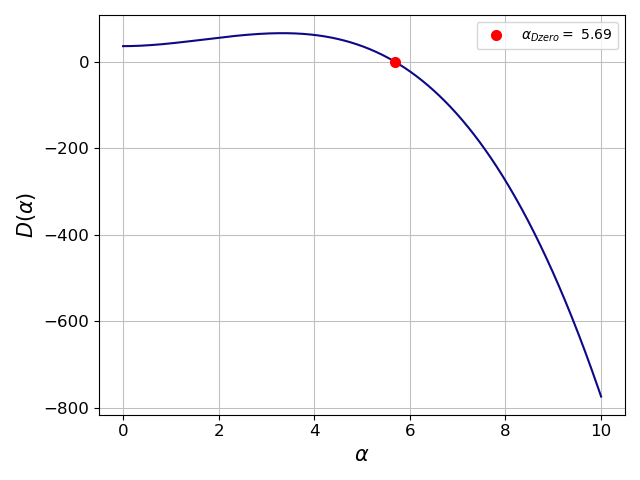

In [42]:
MB.colorloop = [ cm.plasma.colors[120*i] for i in range(3) ]

plt_topdenom = spb.plot(denom(N_mat[2]).subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1}), (alpha, 0,10), markers = [{'args':[alpha_Dzero, 0, 'o'], 'markersize':7, 'color': 'red', 'label':r'$\alpha_{Dzero}=$ %.2f' %alpha_Dzero}], xlabel = r'$\alpha$', ylabel = r'$D(\alpha)$', label='', show=False)

## Swapped top and basal parameters
# plt_topdenom = spb.plot(denom(N_mat[2]).subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1}), (alpha, 0,20), markers = [{'args':[alpha_Dzero, 0, 'o'], 'markersize':7, 'color': 'red', 'label':r'$\alpha_{Dzero}=$ %.2f' %alpha_Dzero}], xlabel = r'$\alpha$', ylabel = r'$D(\alpha)$', label='', show=False)

plt_topdenom.show()

### Finding $\alpha_{min}$ and $\alpha_{max}$, i.e. limits of the feasible region

In [87]:
# root_Cstar_val = root_Cstar[1].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:1, d_2:0.1, d_3:0.3})

# Swapped top and basal parameters
root_Cstar_val = root_Cstar[1].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1, r_1:1.3, d_2:0.1, d_3:0.1})

root_Pstar_val = root_Pstar[0]

In [88]:
root_Pstar_val

7.57205547701806

### Plot $C^*(\alpha)$ and $P^*(\alpha)$

[None, None, None, None]

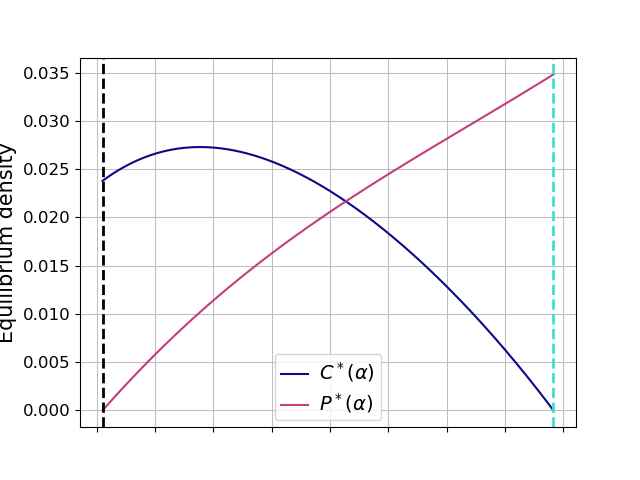

In [45]:
plt_conpred = spb.plot(N_mat[1].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:1, d_2:0.1, d_3:0.3}), N_mat[2].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:1, d_2:0.1, d_3:0.3}), (alpha, root_Pstar_val, root_Cstar_val),  xlabel = r'$\alpha$', ylabel = 'Equilibrium density', label = [r'$C^*(\alpha)$', r'$P^*(\alpha)$'], legend = True, show=False)

##Swapped top and basal parameters
# plt_conpred = spb.plot(N_mat[1].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1, r_1:1.3, d_2:0.1, d_3:0.1}), N_mat[2].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1, r_1:1.3, d_2:0.1, d_3:0.1}), (alpha, root_Pstar_val, root_Cstar_val),  xlabel = r'$\alpha$', ylabel = 'Equilibrium density', label = [r'$C^*(\alpha)$', r'$P^*(\alpha)$'], legend = True, show=False)

ax_conpred = plt_conpred.ax
ax_conpred.axvline( x=root_Pstar_val, color='k', linestyle='--', linewidth=2 )
ax_conpred.axvline( x=root_Cstar_val, color='turquoise', linestyle='--', linewidth=2 )

ax_conpred.set_xticklabels([])
ax_conpred.xaxis.set_label_text("")

plt.setp(ax_conpred.get_legend().get_texts(), fontsize=14)

# plt_conpred.save('Densities_omni.eps', dpi=600, bbox_inches='tight')


# plt_conpred.show()

### Output power

In [89]:
P_out = eps*N_mat[2]*(alpha*k_23*N_mat[1] + (A_mat[2,0]/eps)*N_mat[0] ) 
## Note that alpha*k_13 = A_mat[2,0]/eps

In [90]:
# P_out_1 = P_out.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:1, d_2:0.1, d_3:0.3})

# Swapped top and basal parameters
P_out_1 = P_out.subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1, r_1:1.3, d_2:0.1, d_3:0.1})

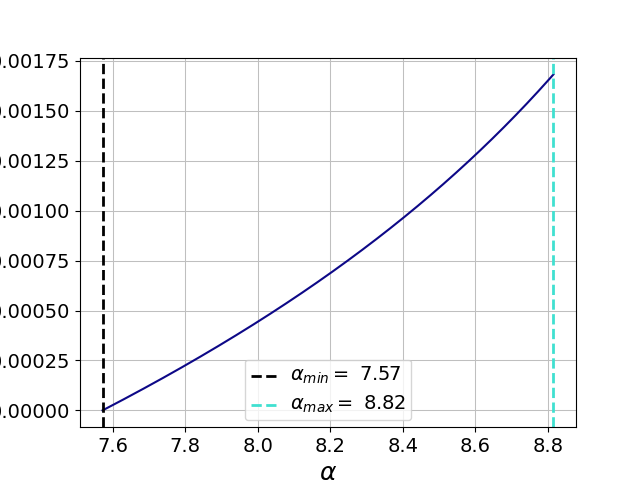

In [125]:
plt_Pout1 = spb.plot(P_out_1, (alpha, root_Pstar_val, root_Cstar_val), xlabel = r'$\alpha$', ylabel = r'$P_{out}^*(\alpha)$', label='', show=False, legend=True, axis=True)

## Swapped top and basal parameters
# plt_Pout1 = spb.plot(P_out_1, (alpha, root_Pstar_val, root_Cstar_val), xlabel = r'$\alpha$', ylabel = r'$P_{out}^*(\alpha)$', label='', show=False, legend=True, axis=True)


ax_Pout1 = plt_Pout1.ax
ax_Pout1.axvline( x=root_Pstar_val, color='k', linestyle='--', linewidth=2, label=r'$\alpha_{min}=$ %.2f' %root_Pstar_val )
ax_Pout1.axvline( x=root_Cstar_val, color='turquoise', linestyle='--', linewidth=2, label=r'$\alpha_{max}=$ %.2f' %root_Cstar_val )
ax_Pout1.legend()

plt.setp(ax_Pout1.get_legend().get_texts(), fontsize=14)

plt_Pout1.save('Pow_omni_swap.eps', dpi=600, bbox_inches='tight')

# plt_Pout1.show()

### Plot $\Omega$

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


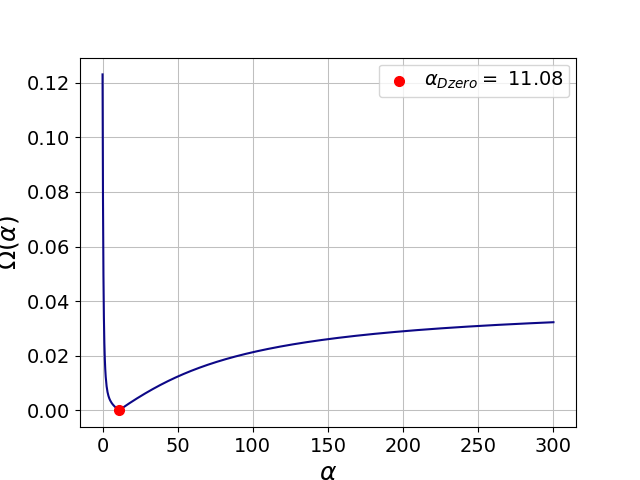

In [127]:
# plt_omega = spb.plot(Omega.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1}), (alpha, 0.01, 300), markers = [{ 'args':[alpha_Dzero, 0, 'o'], 'markersize':7, 'color': 'red', 'label':r'$\alpha_{Dzero}=$ %.2f' %alpha_Dzero }], xlabel = r'$\alpha$', ylabel = r'$\Omega(\alpha)$', label = '', show=False)

## Swapped top and basal level parameters
plt_omega = spb.plot(Omega.subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1}), (alpha, 0.01, 300), markers = [{ 'args':[alpha_Dzero, 0, 'o'], 'markersize':7, 'color': 'red', 'label':r'$\alpha_{Dzero}=$ %.2f' %alpha_Dzero }], xlabel = r'$\alpha$', ylabel = r'$\Omega(\alpha)$', label = '', show=False)

ax_omega = plt_omega.ax
plt.setp(ax_omega.get_legend().get_texts(), fontsize=14)
plt_omega.save('Feas_omni_swap.eps', dpi=600, bbox_inches='tight')
# plt_omega.show()

### $\alpha_{pow} > \alpha_{Dzero}$ case

In [44]:


root_Cstar_val2 = root_Cstar[1].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:0.6, d_2:0.1, d_3:1})

# plt_conpred2 = spb.plot(N_mat[1].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:0.6, d_2:0.1, d_3:1}), (alpha, root_Cstar_val2, 400),  xlabel = r'$\alpha$', ylabel = r'$C^*(\alpha)$', label = '', legend = True, show=False)

# ax_conpred2 = plt_conpred2.ax
# ax_conpred2.axvline( x=root_Cstar_val2, color='goldenrod', linestyle='--', linewidth=2 )
# ax_conpred2.set_xticklabels([])
# ax_conpred2.xaxis.set_label_text("")

# plt_conpred2.save('Cstar_omni_3sp.eps', dpi=600, bbox_inches='tight')

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


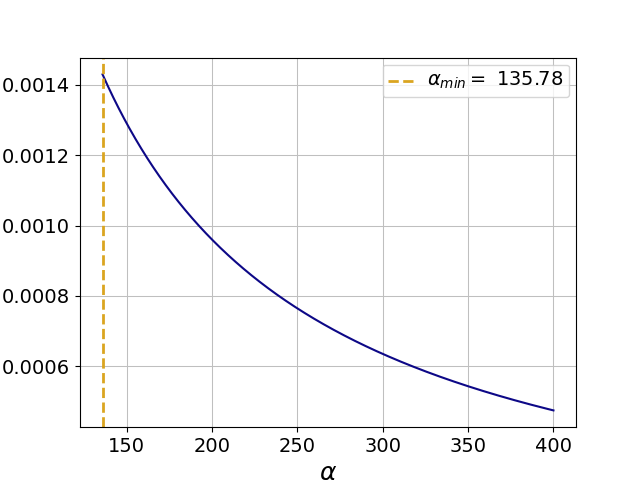

In [113]:
plt_Pout2 = spb.plot(P_out.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:0.6, d_2:0.1, d_3:1}), (alpha, root_Cstar_val2, 400), xlabel = r'$\alpha$', ylabel = r'$P_{out}^*(\alpha)$', label='', show=False, legend=True)

ax_Pout2 = plt_Pout2.ax
ax_Pout2.axvline( x=root_Cstar_val2, color='goldenrod', linestyle='--', linewidth=2, label=r'$\alpha_{min}=$ %.2f' %root_Cstar_val2 )
ax_Pout2.legend()

plt.setp(ax_Pout2.get_legend().get_texts(), fontsize=14)

plt_Pout2.save('Pow2_omni_3sp.eps', dpi=600, bbox_inches='tight')

## Combined plot for 3 species omnivory

### Normal pyramid $a_1=1, a_2=4, a_3=9$

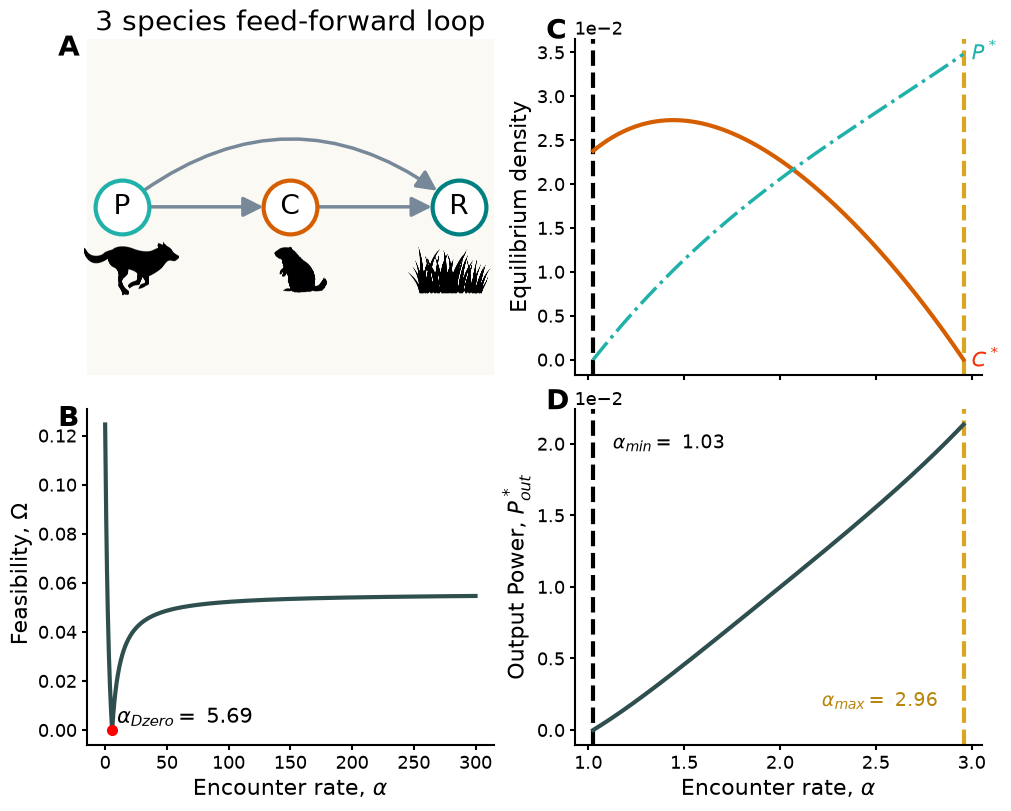

In [47]:

fig = plt.figure(figsize=(10, 8), constrained_layout=True) 
## ^ constrained layout prevents overlaps between subplots

gs = gridspec.GridSpec(ncols=12, nrows=8, figure=fig)

ax2 = fig.add_subplot(gs[0:4, 0:6])
ax1 = fig.add_subplot(gs[4:8, 0:6])
ax3 = fig.add_subplot(gs[0:4, 6:12])
ax4 = fig.add_subplot(gs[4:8, 6:12])
# ax5 = fig.add_subplot(gs[4:8, 6:12])
# ax6 = fig.add_subplot(gs[8:12, 6:12])

# ax1.grid(False)
# # ax2.grid(True)
# ax3.grid(False)
# ax4.grid(False)
# ax5.grid(False)
# ax6.grid(False)

p1 = spb.plot(Omega.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1}), (alpha, 0.01, 300), markers = [{ 'args':[alpha_Dzero, 0, 'o'], 'markersize':7, 'color': 'red'}], xlabel = r'Encounter rate, $\alpha$', ylabel = r' Feasibility, $\Omega$', label = '', ax=ax1, rendering_kw={"color": "darkslategray", "linewidth": 3}, show=False, grid=False)
ax1.text(alpha_Dzero*1.7, 0.005, r'$\alpha_{Dzero}=$ %.2f' %alpha_Dzero, color='k', va='center', fontsize=15)
# ax1.legend()


trophic_loop = netx.Graph()
node_list = ["R", "C", "P"]
# trophic_loop.add_nodes_from(node_list)
for i in range(len(node_list)):
    trophic_loop.add_node(node_list[i], layer=2-i)
pos = netx.multipartite_layout(trophic_loop, subset_key="layer")
# pos = {node: (coords[1], coords[0]) for node, coords in pos.items()}
# pos = netx.kamada_kawai_layout(trophic_loop)
# pos = {'P': (0, 0), 'C': (1, 0), 'R': (2, 0)}
# netx.draw(trophic_chain, pos, node_color='goldenrod', ax=ax2, with_labels = True)
relation_list = [['P', 'C'], ['C', 'R'], ['P', 'R']]
top_edges = [['P', 'C'], ['C', 'R']]
bottom_edges = [['P', 'R']]
trophic_loop = netx.from_edgelist(relation_list, create_using=netx.DiGraph)
netx.draw_networkx_nodes(trophic_loop, pos, nodelist=node_list[2], ax=ax2, node_size=1500, linewidths=3.0, node_color='white', node_shape='o', edgecolors="lightseagreen", alpha=1)
netx.draw_networkx_nodes(trophic_loop, pos, nodelist=node_list[1], ax=ax2, node_size=1500, linewidths=3.0, node_color='white', node_shape='o', edgecolors="#D55E00", alpha=1)
netx.draw_networkx_nodes(trophic_loop, pos, nodelist=node_list[0], ax=ax2, node_size=1500, linewidths=3.0, node_color='white', node_shape='o', edgecolors="teal", alpha=1)
netx.draw_networkx_labels(trophic_loop, pos, ax=ax2, font_size=20, font_color="k")
netx.draw_networkx_edges(trophic_loop, pos, edgelist=top_edges, width=2.5, ax=ax2, node_size=1500, edge_color='lightslategray', connectionstyle='arc3,rad=0', arrowsize=30, alpha=1)
netx.draw_networkx_edges(trophic_loop, pos, edgelist=bottom_edges, width=2.5, ax=ax2, node_size=1500, edge_color='lightslategray', connectionstyle='arc3,rad=-0.4', arrowsize=30, alpha=1)

# Load external images
graph_species = {
    'R': mpimg.imread('Canva_grass.png'),
    'C': mpimg.imread('Canva_rodent.png'),
    'P': mpimg.imread('Canva_canid.png'),
}


# Transform coordinates and overlay images on each node
ax_transform = ax2.transData.transform
fig_transform = fig.transFigure.inverted().transform

imsize = 0.1  # Relative size of the image icon

for node, (x, y) in pos.items():
    if node in graph_species:
        # Convert data coordinates to figure-relative coordinates
        xx, yy = ax_transform((x, y))
        xa, ya = fig_transform((xx, yy))
        
        # Create a small axes at the node position to display the image
        image_ax = fig.add_axes([xa - imsize / 1.2, ya - imsize / 1.5, imsize, imsize])
        image_ax.imshow(graph_species[node])
        image_ax.set_aspect('equal')
        image_ax.axis('off')

# netx.draw(trophic_loop, pos, node_color='goldenrod', ax=ax2, with_labels=True, font_size = 15, node_size=500, width = 2.5, arrowsize=20)
# netx.draw_networkx_edge_labels(trophic_chain, pos, ax=ax2, font_size=15, verticalalignment='bottom', edge_labels={('P','C'):r'$\alpha$', ('C','R'):r'$\alpha$'})


ax2.set_axis_on()
ax2.spines[:].set_visible(False)
ax2.set_title('3 species feed-forward loop', fontsize=20)
ax2.set_facecolor("#FBF9F4")

p2 = spb.plot(N_mat[1].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:1, d_2:0.1, d_3:0.3}), N_mat[2].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:1, d_2:0.1, d_3:0.3}), (alpha, root_Pstar_val, root_Cstar_val),  xlabel = '', ylabel = 'Equilibrium density', label = ['', ''], ax=ax3, rendering_kw=[dict(color="#D55E00", linewidth = 3), dict(color="lightseagreen", linewidth = 2.5, linestyle="-.")], show=False, grid=False)
ax3.axvline( x=root_Pstar_val, color='k', linestyle='--', linewidth=3 )
ax3.axvline( x=root_Cstar_val, color='goldenrod', linestyle='--', linewidth=3 )
ax3.text(3, 0.035, r'$P^*$', color='lightseagreen', va='center', fontsize=15)
ax3.text(3, 0.0, r'$C^*$', color='xkcd:vermillion', va='center', fontsize=15)
ax3.set_xticklabels([])
ax3.xaxis.set_label_text("")
ax3.ticklabel_format(axis='y', style='sci', scilimits=(0,0))


p3 = spb.plot(P_out_1, (alpha, root_Pstar_val, root_Cstar_val), xlabel = r'Encounter rate, $\alpha$', ylabel = r'Output Power, $P_{out}^*$', label='', ax=ax4, rendering_kw={"color": "darkslategray", "linewidth": 3}, show=False, grid=False)
ax4.axvline( x=root_Pstar_val, color='k', linestyle='--', linewidth=3 )
ax4.axvline( x=root_Cstar_val, color='goldenrod', linestyle='--', linewidth=3 )
ax4.text(root_Pstar_val*1.1, 0.020, r'$\alpha_{min}=$ %.2f' %root_Pstar_val, color='k', va='center', fontsize=14)
ax4.text(root_Cstar_val*0.75, 0.002, r'$\alpha_{max}=$ %.2f' %root_Cstar_val, color='darkgoldenrod', va='center', fontsize=14)
ax4.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
# ax4.legend()

# p4 = spb.plot(N_mat[1].subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:0.6, d_2:0.1, d_3:1}), (alpha, root_Cstar_val2, 400),  xlabel = '', ylabel = r'Herbivore density, $C^*$', label = '', ax=ax5, rendering_kw={"color": "#D55E00", "linewidth": 3}, show = False, grid=False)
# ax5.axvline( x=root_Cstar_val2, color='#EDBB99', linestyle='--', linewidth=3 )
# ax5.set_xticklabels([])
# ax5.xaxis.set_label_text("")
# ax5.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# p5 = spb.plot(P_out.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1, r_1:0.6, d_2:0.1, d_3:1}), (alpha, root_Cstar_val2, 400), xlabel = r'Encounter rate, $\alpha$', ylabel = r'Output power, $P_{out}^*$', label='', ax=ax6, rendering_kw={"color": "darkslategray", "linewidth": 3}, show = False, grid=False)
# ax6.axvline( x=root_Cstar_val2, color='#EDBB99', linestyle='--', linewidth=3 )
# ax6.text(root_Cstar_val2*1.1, 0.0005, r'$\alpha_{min}=$ %.2f' %root_Cstar_val2, color='#2F1808', va='center', fontsize=15)
# ax6.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
# # ax6.legend()

## Add corner labels
ax2.annotate('A', xy=(0, 0.95), xytext=(-0.07, 0.95), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax1.annotate('B', xy=(0, 0.95), xytext=(-0.07, 0.95), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax3.annotate('C', xy=(0, 1), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax4.annotate('D', xy=(0, 1), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
# ax5.annotate('E', xy=(0, 1), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
# ax6.annotate('F', xy=(0, 1), xytext=(-0.07, 1), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)

p1.draw()
p2.draw()
p3.draw()
# p4.draw()
# p5.draw()

plt.show()
# plt.savefig('3_omni.eps', dpi=600, bbox_inches='tight')
# plt.close('all')

### Inverted pyramid $a_1=9, a_2=4, a_3=1$

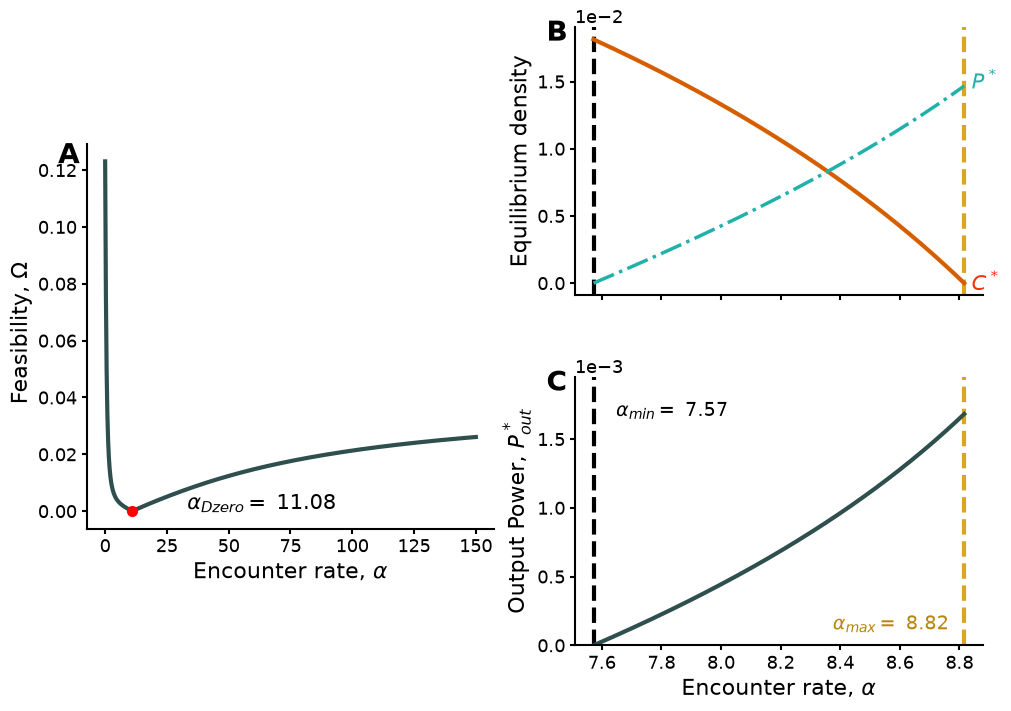

In [102]:
# MB.colorloop = [ cm.plasma.colors[120*i] for i in range(3) ]

fig = plt.figure(figsize=(10, 7), constrained_layout=True) 
## ^ constrained layout prevents overlaps between subplots

gs = gridspec.GridSpec(ncols=6, nrows=6, figure=fig)

ax1 = fig.add_subplot(gs[1:5, 0:3])
ax2 = fig.add_subplot(gs[0:3, 3:])
ax3 = fig.add_subplot(gs[3:6, 3:])

p1 = spb.plot(Omega.subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1}), (alpha, 0.01, 150), markers = [{ 'args':[alpha_Dzero, 0, 'o'], 'markersize':7, 'color': 'red' }], xlabel = r'Encounter rate, $\alpha$', ylabel = r' Feasibility, $\Omega$', label = '', ax=ax1, rendering_kw={"color": "darkslategray", "linewidth": 3}, show=False, grid=False)
ax1.text(alpha_Dzero*3, 0.0025, r'$\alpha_{Dzero}=$ %.2f' %alpha_Dzero, color='k', va='center', fontsize=15)
# ax1.legend()

p2 = spb.plot(N_mat[1].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1, r_1:1.3, d_2:0.1, d_3:0.1}), N_mat[2].subs({a_1:9, a_2:4, a_3:1, k_12:2, k_23:1, k_13:1, eps:0.1, r_1:1.3, d_2:0.1, d_3:0.1}), (alpha, root_Pstar_val, root_Cstar_val),  xlabel = '', ylabel = 'Equilibrium density', label = ['', ''], ax=ax2, rendering_kw=[dict(color="#D55E00", linewidth = 3), dict(color="lightseagreen", linewidth = 2.5, linestyle="-.")], show=False, grid=False)
ax2.axvline( x=root_Pstar_val, color='k', linestyle='--', linewidth=3 )
ax2.axvline( x=root_Cstar_val, color='goldenrod', linestyle='--', linewidth=3 )
ax2.text(root_Cstar_val + 0.025, 0.015, r'$P^*$', color='lightseagreen', va='center', fontsize=15)
ax2.text(root_Cstar_val + 0.025, 0.0, r'$C^*$', color='xkcd:vermillion', va='center', fontsize=15)
ax2.set_xticklabels([])
ax2.xaxis.set_label_text("")
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))


p3 = spb.plot(P_out_1, (alpha, root_Pstar_val, root_Cstar_val), xlabel = r'Encounter rate, $\alpha$', ylabel = r'Output Power, $P_{out}^*$', label='', ax=ax3, rendering_kw={"color": "darkslategray", "linewidth": 3}, show=False, grid=False)
ax3.axvline( x=root_Pstar_val, color='k', linestyle='--', linewidth=3 )
ax3.axvline( x=root_Cstar_val, color='goldenrod', linestyle='--', linewidth=3 )
ax3.text(root_Pstar_val*1.01, 0.0017, r'$\alpha_{min}=$ %.2f' %root_Pstar_val, color='k', va='center', fontsize=14)
ax3.text(root_Cstar_val*0.95, 0.00015, r'$\alpha_{max}=$ %.2f' %root_Cstar_val, color='darkgoldenrod', va='center', fontsize=14)
ax3.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax3.set_ylim(top=0.00195)

# ax3.legend()


## Add corner labels
ax1.annotate('A', xy=(0, 0.95), xytext=(-0.07, 0.95), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax2.annotate('B', xy=(0, 0.95), xytext=(-0.07, 0.95), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)
ax3.annotate('C', xy=(0, 0.95), xytext=(-0.07, 0.95), fontsize=20, fontweight='bold', xycoords='axes fraction', annotation_clip=False)

p1.draw()
p2.draw()
p3.draw()

plt.show()
# plt.savefig('3_omni_swap.png', dpi=600, bbox_inches='tight')
# plt.close('all')

## Writing down $\alpha_{pow}$ and densities in terms of ratios $\rho_1 = r_1/d_3$ and $\rho_2 = d_2/d_3$

In [128]:
rho_1, rho_2 = symbols('rho_1 rho_2', positive=True, real=True)

### The two roots of $C^*(\alpha)$

In [129]:
Cstar_0_rho1 = (a_1*k_23 + a_3*eps*k_12*rho_1 - sqrt(a_1**2*k_23**2 - 4*a_1*a_3*rho_2**2*eps*k_13**2 + 4*a_1*a_3*rho_2*eps*k_12*k_13 - 4*a_1*a_3*rho_2*eps*k_23*k_13*rho_1 + 2*a_1*a_3*eps*k_12*k_23*rho_1 + a_3**2*eps**2*k_12**2*rho_1**2))/(2*eps*k_13*(rho_2*k_13 - k_12 + k_23*rho_1))

In [130]:
Cstar_0_rho2 = (a_1*k_23 + a_3*eps*k_12*rho_1 + sqrt(a_1**2*k_23**2 - 4*a_1*a_3*rho_2**2*eps*k_13**2 + 4*a_1*a_3*rho_2*eps*k_12*k_13 - 4*a_1*a_3*rho_2*eps*k_23*k_13*rho_1 + 2*a_1*a_3*eps*k_12*k_23*rho_1 + a_3**2*eps**2*k_12**2*rho_1**2))/(2*eps*k_13*(rho_2*k_13 - k_12 + k_23*rho_1))

## Plot $\alpha_{pow}$ as a function of $\rho_1$ and $\rho_2$

### To avoid infinities, we replace them with NaNs

<lambdifygenerated-184>:2: RuntimeWarning: invalid value encountered in sqrt


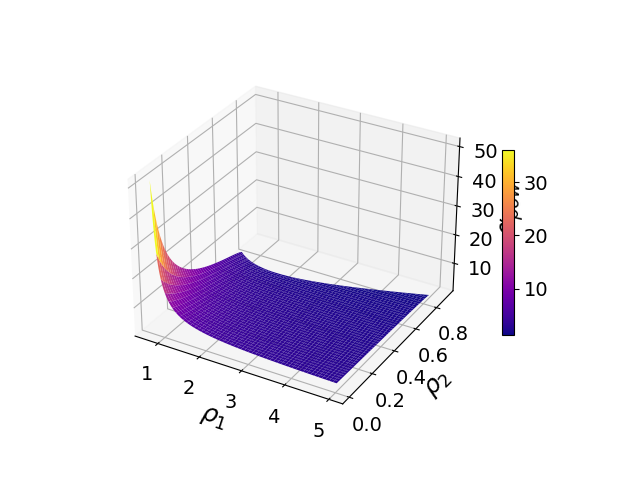

In [145]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

alpha_pow = Max( Cstar_0_rho1.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1}), Cstar_0_rho2.subs({a_1:1, a_2:4, a_3:9, k_12:2, k_23:3, k_13:3, eps:0.1}) )

alpha_pow_num = lambdify((rho_1, rho_2), alpha_pow, 'numpy')

rho1_vals = np.linspace(0.75, 5, 1000)
rho2_vals = np.linspace(0.01, 0.9, 1000)

RHO1, RHO2 = np.meshgrid(rho1_vals, rho2_vals)

alpha_pow_3d = alpha_pow_num(RHO1, RHO2)

alpha_pow_filtered = np.where(np.isinf(alpha_pow_3d), np.nan, alpha_pow_3d)

alpha_pow_rho = ax.plot_surface(RHO1, RHO2, alpha_pow_filtered, cmap='plasma')

ax.set_xlabel(r'$\rho_1$')
ax.set_ylabel(r'$\rho_2$')
ax.set_zlabel(r'$\alpha_{pow}$')
# ax.set_title(r'$\alpha$ maximizing output power')

fig.colorbar(alpha_pow_rho, shrink=0.5, aspect=15)

plt.show()

In [148]:
## Save figure as .eps or .png 

plt.savefig('alphapow_rho_omni.eps', dpi=600, bbox_inches='tight')

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


## $\delta_{min}$ as a function of $\rho_1$ and $\rho_2$

### Note that $\alpha_{Dzero}$ is the same as $\alpha_{geom}$, i.e. the point at which feasibility is minimum.

<lambdifygenerated-192>:2: RuntimeWarning: invalid value encountered in sqrt


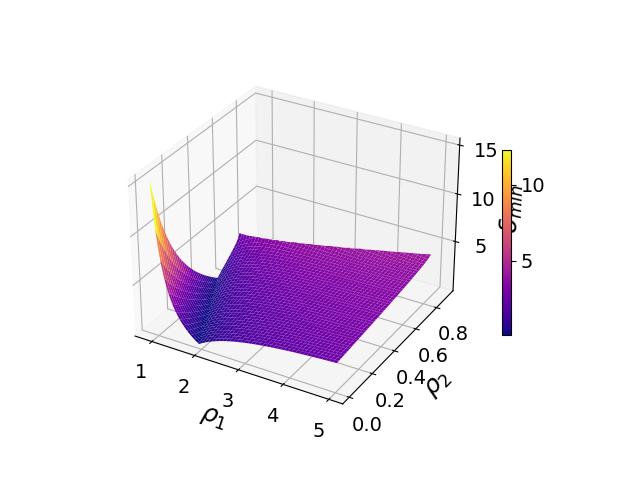

In [157]:
fig2, ax2 = plt.subplots(subplot_kw={"projection": "3d"})

delta_min = abs(alpha_pow - alpha_Dzero)

delta_min_num = lambdify((rho_1, rho_2), delta_min, 'numpy')

rho1_vals = np.linspace(0.9, 5, 1000)
rho2_vals = np.linspace(0.01, 0.9, 1000)

RHO1, RHO2 = np.meshgrid(rho1_vals, rho2_vals)

delta_min_3d = delta_min_num(RHO1, RHO2)

delta_min_filtered = np.where(np.isinf(delta_min_3d), np.nan, delta_min_3d)

delta_min_rho = ax2.plot_surface(RHO1, RHO2, delta_min_filtered, cmap='plasma')

ax2.set_xlabel(r'$\rho_1$')
ax2.set_ylabel(r'$\rho_2$')
ax2.set_zlabel(r'$\delta_{min}$')
# ax.set_title(r'$\alpha$ maximizing output power')

fig2.colorbar(delta_min_rho, shrink=0.5, aspect=20)

plt.show()



In [159]:
## Save figure as .eps or .png 

plt.savefig('deltamin_rho_omni.eps', dpi=600, bbox_inches='tight')

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
